# 01 — EDA Titanic

**EDA (Exploratory Data Analysis)** = "kenalan" dengan data: isinya apa, mana yang kosong, kolom mana yang berhubungan dengan target.

Cara pakai:
- **Di laptop:** pilih kernel **Python (kaggle)** → jalankan sel dari atas.
- **Di GPU Colab (VS Code):** pilih kernel **Colab** → sel setup akan `git clone` repo, sel token akan minta token Kaggle.

Aturan main: sel di bagian **Eksplorasi** bebas kamu ubah. Kode yang mau dipakai lagi → minta Claude pindahkan ke `src/`.

In [1]:
# === Sel SETUP — jalankan PERTAMA, dan jalankan ulang setelah Claude mengubah file .py ===
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/mrizkykhatami/titanic.git"   # ganti kalau nama repo berbeda

def _remote():
    if "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
        return "kaggle"
    try:
        import google.colab  # noqa: F401
        return "colab"
    except ImportError:
        return None

where = _remote()
if where:  # Kaggle / Colab: ambil kode terbaru dari GitHub
    ROOT = (Path("/kaggle/working") if where == "kaggle" else Path("/content")) / "titanic"
    if ROOT.exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
else:      # Laptop: pakai folder repo ini langsung
    ROOT = Path.cwd().parent if Path.cwd().name in ("notebooks", "train") else Path.cwd()
    if ROOT.name == "kernels":
        ROOT = ROOT.parent

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("jalan di:", where or "local", "| ROOT =", ROOT)

jalan di: local | ROOT = c:\Users\M Rizky Khatami\kaggle\titanic


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# === Token Kaggle — hanya diperlukan di Colab (di laptop sudah ada ~/.kaggle/access_token) ===
import os
from getpass import getpass
if where == "colab" and not os.environ.get("KAGGLE_API_TOKEN"):
    os.environ["KAGGLE_API_TOKEN"] = getpass("Tempel Kaggle API token: ")  # tidak tampil & tidak tersimpan di notebook

## 1. Muat data

In [4]:
from src.data import load
train, test = load()
train.head()

[data] C:\Users\M Rizky Khatami\kaggle\titanic\data | train=(891, 12) test=(418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Berapa nilai kosong (NaN) per kolom?
train.isna().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

## 2. Eksplorasi (bebas diubah)

In [6]:
# Persentase selamat secara keseluruhan
train["Survived"].mean()

np.float64(0.3838383838383838)

In [7]:
# Persentase selamat per jenis kelamin & kelas tiket
train.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(2)

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


In [8]:
# Persentase selamat per pelabuhan keberangkatan (C = Cherbourg, Q = Queenstown, S = Southampton)
train.groupby("Embarked")["Survived"].agg(["mean", "count"]).round(2)

,mean,count
Embarked,,
C,0.55,168
Q,0.39,77
S,0.34,644


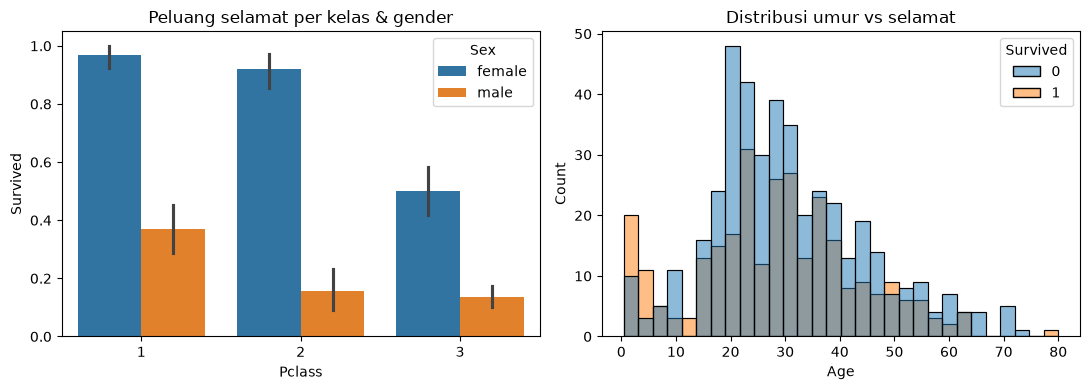

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=train, x="Pclass", y="Survived", hue="Sex", ax=axes[0])
axes[0].set_title("Peluang selamat per kelas & gender")
sns.histplot(data=train, x="Age", hue="Survived", bins=30, ax=axes[1])
axes[1].set_title("Distribusi umur vs selamat")
plt.tight_layout()

## 3. Feature engineering (kode ada di `src/features.py`)

In [10]:
from src.features import add_features
feat = add_features(train)
feat[["Name", "Title", "FamilySize", "IsAlone", "Deck", "Survived"]].head(10)

,Name,Title,FamilySize,IsAlone,Deck,Survived
0,"Braund, Mr. Owen Harris",Mr,2,0,U,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,C,1
2,"Heikkinen, Miss. Laina",Miss,1,1,U,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,C,1
4,"Allen, Mr. William Henry",Mr,1,1,U,0
5,"Moran, Mr. James",Mr,1,1,U,0
6,"McCarthy, Mr. Timothy J",Mr,1,1,E,0
7,"Palsson, Master. Gosta Leonard",Master,5,0,U,0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs,3,0,U,1
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs,2,0,U,1


In [11]:
feat.groupby("Title")["Survived"].agg(["mean", "count"]).round(2)

,mean,count
Title,,
Master,0.57,40
Miss,0.70,185
Mr,0.16,517
Mrs,0.79,126
Rare,0.35,23


## 4. Cross-Validation (kode ada di `src/train.py`)

Model dilatih 5 kali (5-fold). Skor **CV** = seberapa akurat tebakan model pada data yang tidak pernah ia lihat.

In [12]:
from src.train import run_cv
result = run_cv(model="hgb", n_splits=5, seed=42)
result

[data] C:\Users\M Rizky Khatami\kaggle\titanic\data | train=(891, 12) test=(418, 11)
  fold 0: accuracy = 0.8547
  fold 1: accuracy = 0.8483
  fold 2: accuracy = 0.8202
  fold 3: accuracy = 0.8258
  fold 4: accuracy = 0.8258
CV accuracy (OOF) = 0.8350 | per-fold 0.8350 ± 0.0138
[saved] C:\Users\M Rizky Khatami\kaggle\titanic\outputs\hgb_s42


{'name': 'hgb_s42',
 'model': 'hgb',
 'n_splits': 5,
 'seed': 42,
 'env': 'local',
 'cv_accuracy': 0.83502,
 'fold_mean': 0.83499,
 'fold_std': 0.01381,
 'fold_scores': [0.85475, 0.84831, 0.82022, 0.82584, 0.82584],
 'seconds': 1.4,
 'time': '2026-10-28 22:52:55'}

In [13]:
# Bandingkan beberapa model sekaligus
import pandas as pd
pd.DataFrame([run_cv(model=m) for m in ["logreg", "rf", "hgb"]])[["name", "cv_accuracy", "fold_std"]]

[data] C:\Users\M Rizky Khatami\kaggle\titanic\data | train=(891, 12) test=(418, 11)
  fold 0: accuracy = 0.8492
  fold 1: accuracy = 0.8315
  fold 2: accuracy = 0.7921
  fold 3: accuracy = 0.8258
  fold 4: accuracy = 0.8483
CV accuracy (OOF) = 0.8294 | per-fold 0.8294 ± 0.0208
[saved] C:\Users\M Rizky Khatami\kaggle\titanic\outputs\logreg_s42
[data] C:\Users\M Rizky Khatami\kaggle\titanic\data | train=(891, 12) test=(418, 11)
  fold 0: accuracy = 0.8547
  fold 1: accuracy = 0.8371
  fold 2: accuracy = 0.8202
  fold 3: accuracy = 0.8315
  fold 4: accuracy = 0.8539
CV accuracy (OOF) = 0.8395 | per-fold 0.8395 ± 0.0133
[saved] C:\Users\M Rizky Khatami\kaggle\titanic\outputs\rf_s42
[data] C:\Users\M Rizky Khatami\kaggle\titanic\data | train=(891, 12) test=(418, 11)
  fold 0: accuracy = 0.8547
  fold 1: accuracy = 0.8483
  fold 2: accuracy = 0.8202
  fold 3: accuracy = 0.8258
  fold 4: accuracy = 0.8258
CV accuracy (OOF) = 0.8350 | per-fold 0.8350 ± 0.0138
[saved] C:\Users\M Rizky Khatami\

,name,cv_accuracy,fold_std
0,logreg_s42,0.82941,0.02076
1,rf_s42,0.83951,0.01329
2,hgb_s42,0.83502,0.01381


## 5. Langkah berikutnya
- File `outputs/<nama>/submission.csv` siap dikirim ke Kaggle.
- Ide eksperimen: tambah feature baru di `src/features.py`, ganti hyperparameter di `configs/`, atau gabungkan beberapa model (ensemble).